In [1]:
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
warnings.filterwarnings("ignore")
import decoupler as dc
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
sc.settings.set_figure_params(dpi=150, facecolor="white")
sc.settings.figdir = r"C:\Users\taylorhearn\Desktop\scRNA\in_depth"
figdir = r"C:\Users\taylorhearn\Desktop\scRNA\in_depth"
leiden_resolution = 0.6

c:\Users\taylorhearn\AppData\Local\miniforge3\envs\sequencing\lib\site-packages\louvain\__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
cluster_colourmap = {
    "0": "#F5C423",  # amber
    "1": "#5B5DE6",  # indigo
    "2": "#E16ED1",  # magenta
    "3": "#2E9BD3",  # azure
    "4": "#8B3FD1",  # violet
    "5": "#F06B2D",  # orange (instead of red)
    "6": "#C32A71",  # raspberry
    "7": "#238F42",  # green
    "8": "#A7C83A",  # lime
}
condition_mapping = {"Bead" : "Vasculature", 
                     "FL_Chip_minus" : "iFL_V+", 
                     "FL_Chip_plus" : "tFL_V+",
                       "FL_ULA_minus" : "iFL_V-", 
                       "FL_ULA_plus" : "tFL_V-",
                       "rLN_Chip_minus" : "irLN_V+",
                       "rLN_ULA_minus" : "irLN_V-",}
condition_colormap = {"Vasculature": "#E8EB5E", 
                      "iFL_V+": "#C51BCE", 
                      "tFL_V+": "#2737FB",
                      "iFL_V-": "#E778ED",
                      "tFL_V-": "#848DFD",
                      "irLN_V+": "#5B9514",
                      "irLN_V-": "#B8ED78"}


clean_matrix = r"C:\Users\taylorhearn\Desktop\scRNA\adata_clustered_res_0_6.h5ad"
res_0_6 = sc.read_h5ad(clean_matrix)
res_0_6.obs["condition"] = res_0_6.obs["condition"].replace(condition_mapping, inplace=False)

In [ ]:
# scanpy's `palette` applies a single palette to ALL panels, so it can't take a
# list of one palette per color. Instead, assign each categorical's colours into
# .uns (ordered to match its categories) and let umap pick them up automatically.
res_0_6.obs["clusters"] = res_0_6.obs["clusters"].astype("category")
res_0_6.obs["condition"] = res_0_6.obs["condition"].astype("category")
res_0_6.obs["sample"] = res_0_6.obs["sample"].astype("category")

res_0_6.uns["clusters_colors"] = [cluster_colourmap[c] for c in res_0_6.obs["clusters"].cat.categories]
res_0_6.uns["condition_colors"] = [condition_colormap[c] for c in res_0_6.obs["condition"].cat.categories]
res_0_6.uns["sample_colors"] = [
    plt.matplotlib.colors.to_hex(c)
    for c in plt.get_cmap("tab20").colors[:res_0_6.obs["sample"].cat.categories.size]
]

sc.pl.umap(res_0_6, color=["clusters", "sample", "condition"], wspace=0.4, ncols=2,
           save="_overview.png", show=True)

In [ ]:
def highlight_umap(adata, groupby, size=10, ncols=4, na_color="lightgrey", savefig=None, palette = None):
    """Highlight one category at a time on the full UMAP (others greyed out)."""
    groups = list(adata.obs[groupby].cat.categories) if hasattr(adata.obs[groupby], "cat") \
        else sorted(adata.obs[groupby].unique())
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(
        nrows=nrows, ncols=ncols,
        figsize=(4 * ncols, 4 * nrows),
        gridspec_kw={"wspace": 0.3, "hspace": 0.3},
    )
    axes = np.atleast_1d(axes).ravel()
    for i, (ax, group) in enumerate(zip(axes, groups)):
        sc.pl.umap(
            adata, color=groupby, groups=[group], na_color=na_color,
            size=size, title=str(group), legend_loc=None, frameon=False, show=False, ax=ax, palette=[palette[group]] if palette else None,    
        )
    for ax in axes[len(groups):]:
        ax.axis("off")
    if savefig:
        plt.savefig(savefig, bbox_inches="tight")
    plt.show()


highlight_umap(res_0_6, "condition", size=10, ncols=4,
               savefig=os.path.join(figdir, "umap_condition_highlight.png"), palette=condition_colormap)

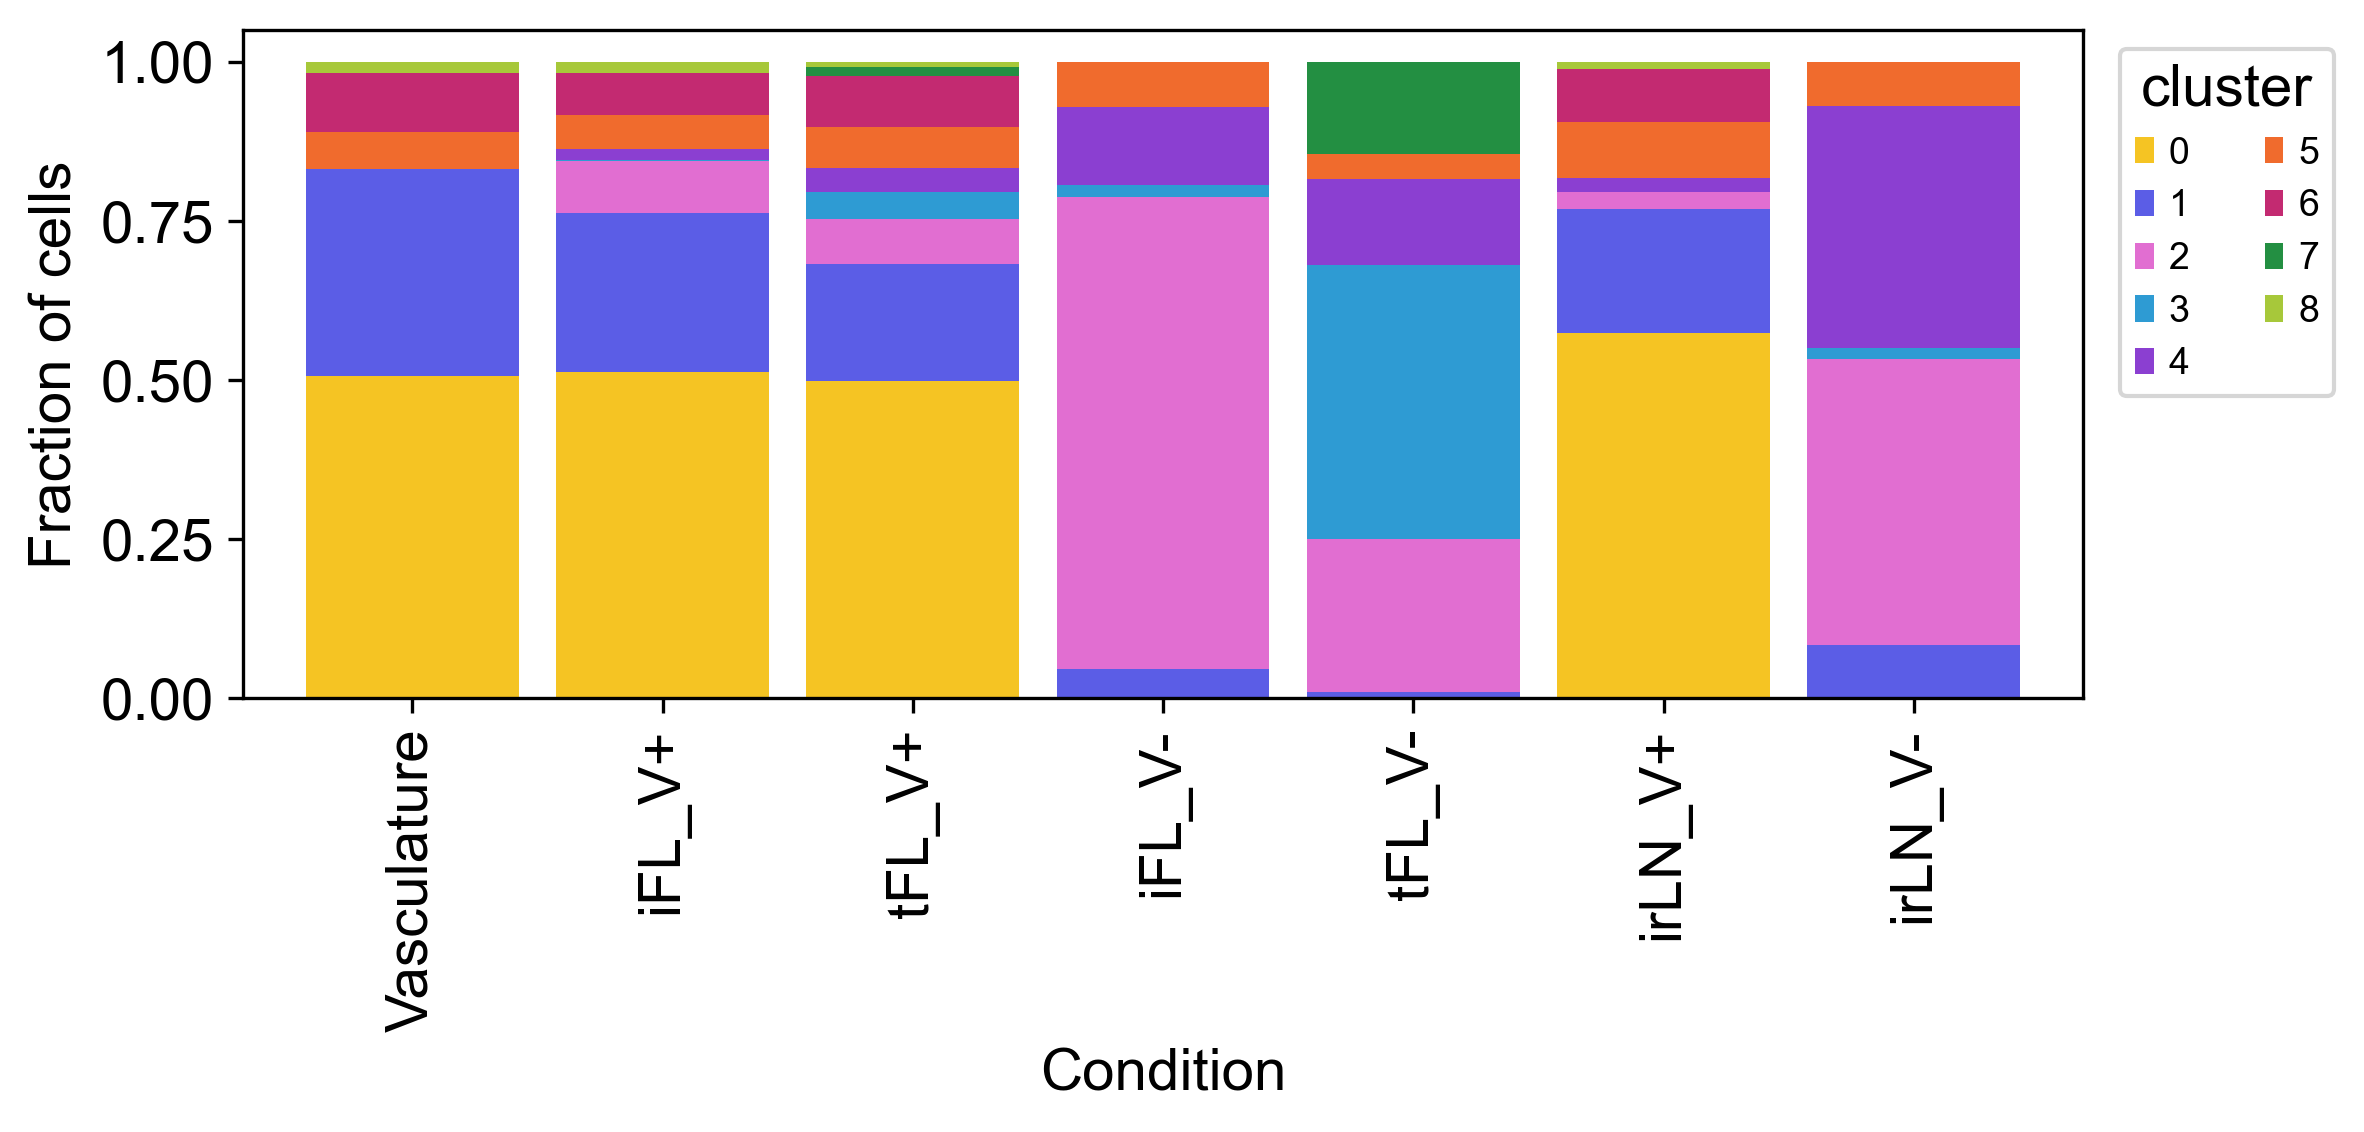

In [4]:
comp = pd.crosstab(res_0_6.obs["condition"], res_0_6.obs["clusters"], normalize="index")
ax = comp.plot(kind="bar", stacked=True, figsize=(8, 4),  color=[cluster_colourmap[str(c)] for c in comp.columns], width=0.85, grid = False)
ax.set_ylabel("Fraction of cells")
ax.set_xlabel("Condition")
ax.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(figdir, "composition_per_condition.png"), bbox_inches="tight")
plt.show()
comp.round(3).to_csv(os.path.join(figdir, "composition_per_condition.csv"))




['Vasculature', 'tFL_V+', 'iFL_V+', 'tFL_V-', 'iFL_V-', 'irLN_V+', 'irLN_V-']
Categories (7, object): ['Vasculature', 'iFL_V+', 'tFL_V+', 'iFL_V-', 'tFL_V-', 'irLN_V+', 'irLN_V-']
['6', '0']
Categories (2, object): ['0', '6']
condition
Vasculature    5168
iFL_V+         9559
tFL_V+         5369
iFL_V-           19
tFL_V-           16
irLN_V+        4239
irLN_V-           1
dtype: int64


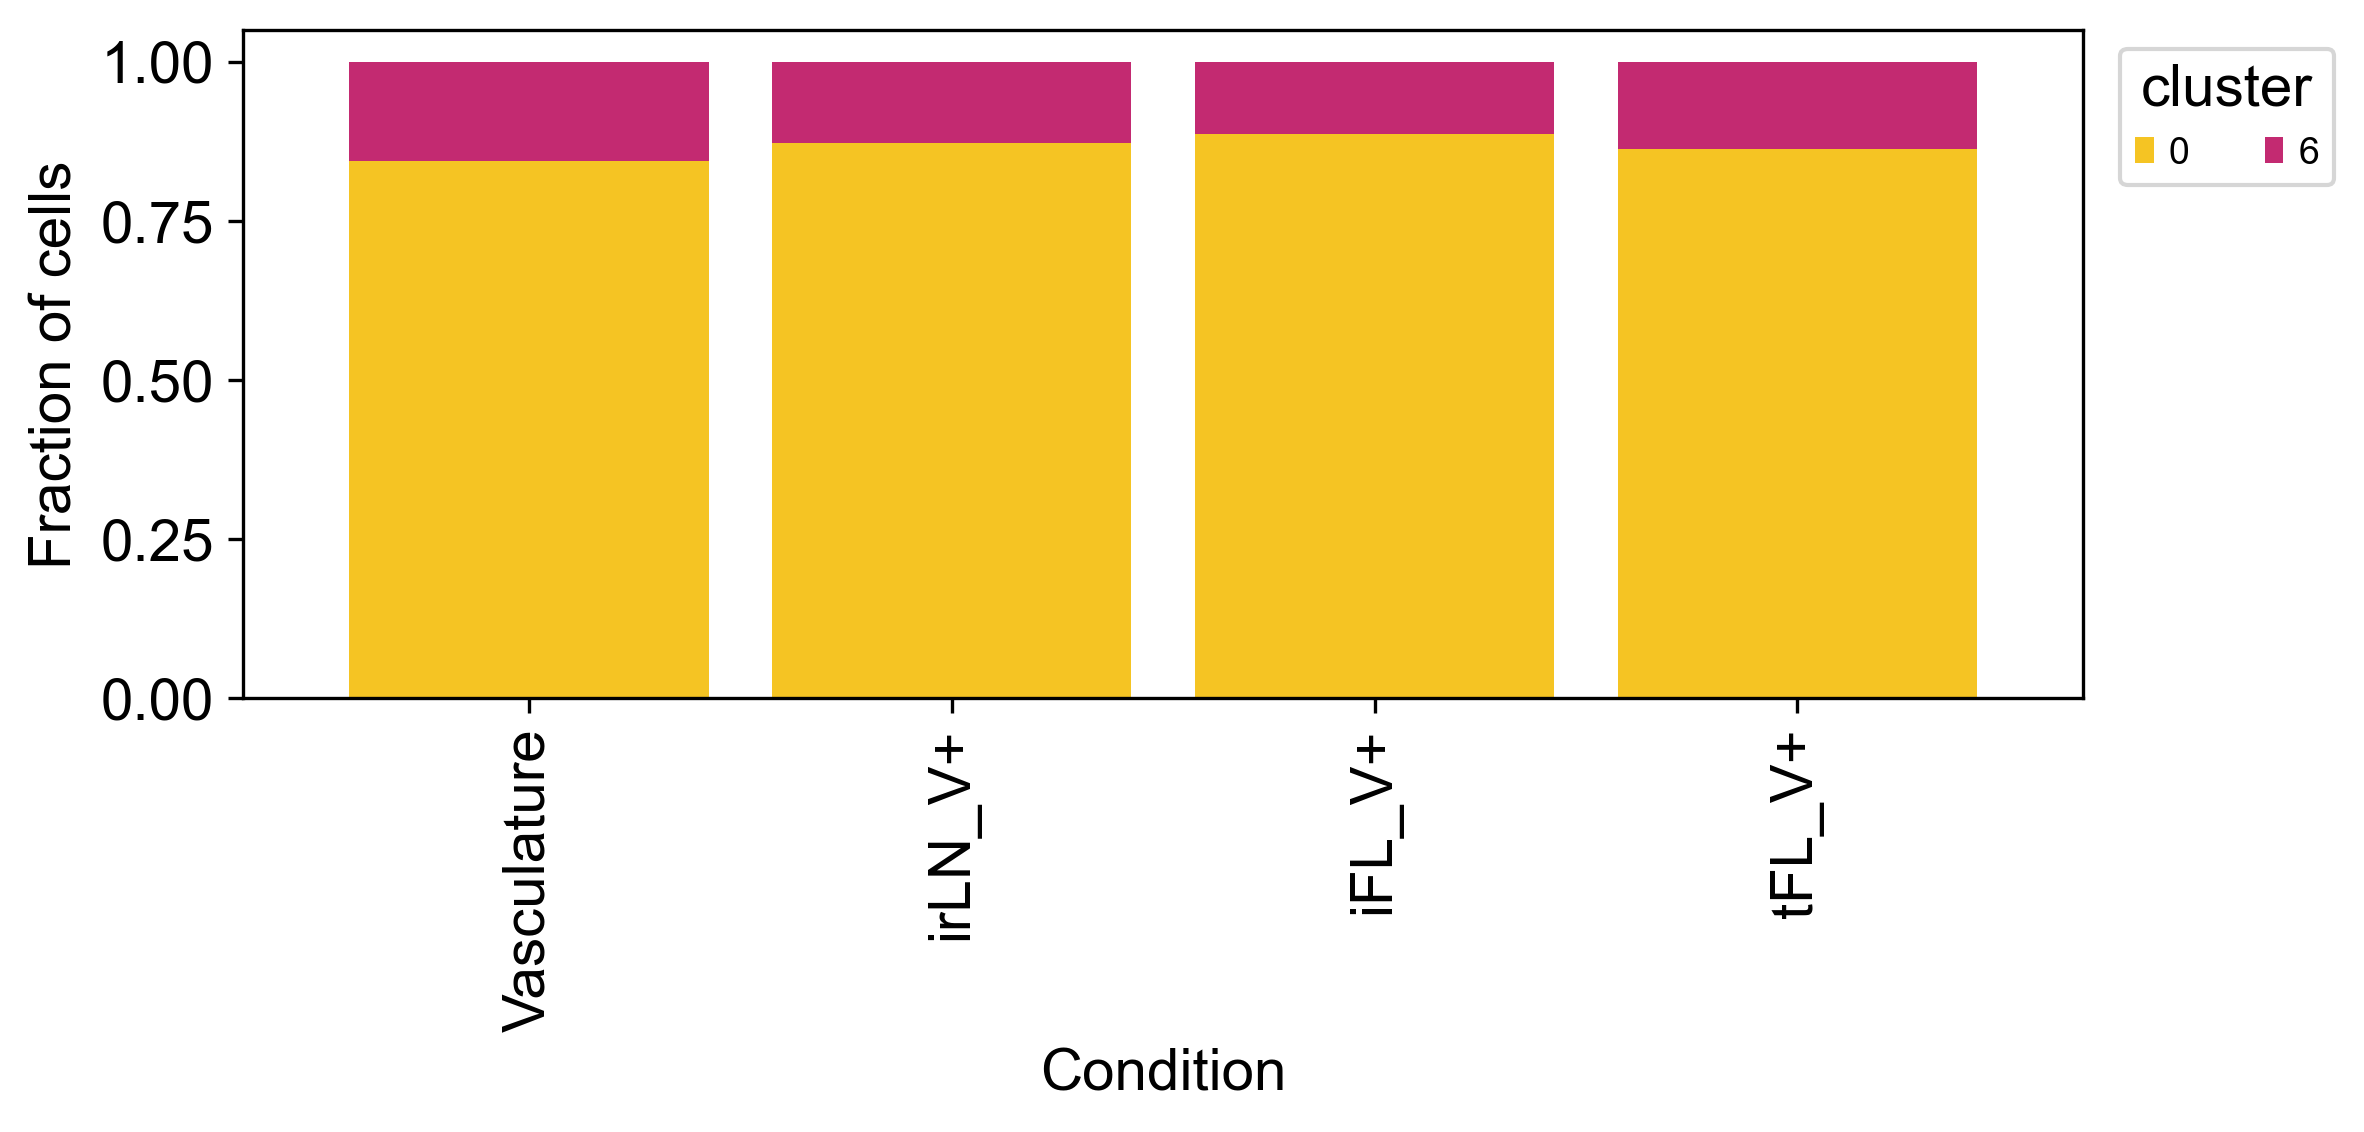

['Vasculature', 'tFL_V+', 'iFL_V+', 'tFL_V-', 'iFL_V-', 'irLN_V-', 'irLN_V+']
Categories (7, object): ['Vasculature', 'iFL_V+', 'tFL_V+', 'iFL_V-', 'tFL_V-', 'irLN_V+', 'irLN_V-']
['1', '8', '5']
Categories (3, object): ['1', '5', '8']
condition
Vasculature    3442
iFL_V+         5297
tFL_V+         2381
iFL_V-          716
tFL_V-          427
irLN_V+        1899
irLN_V-         418
dtype: int64


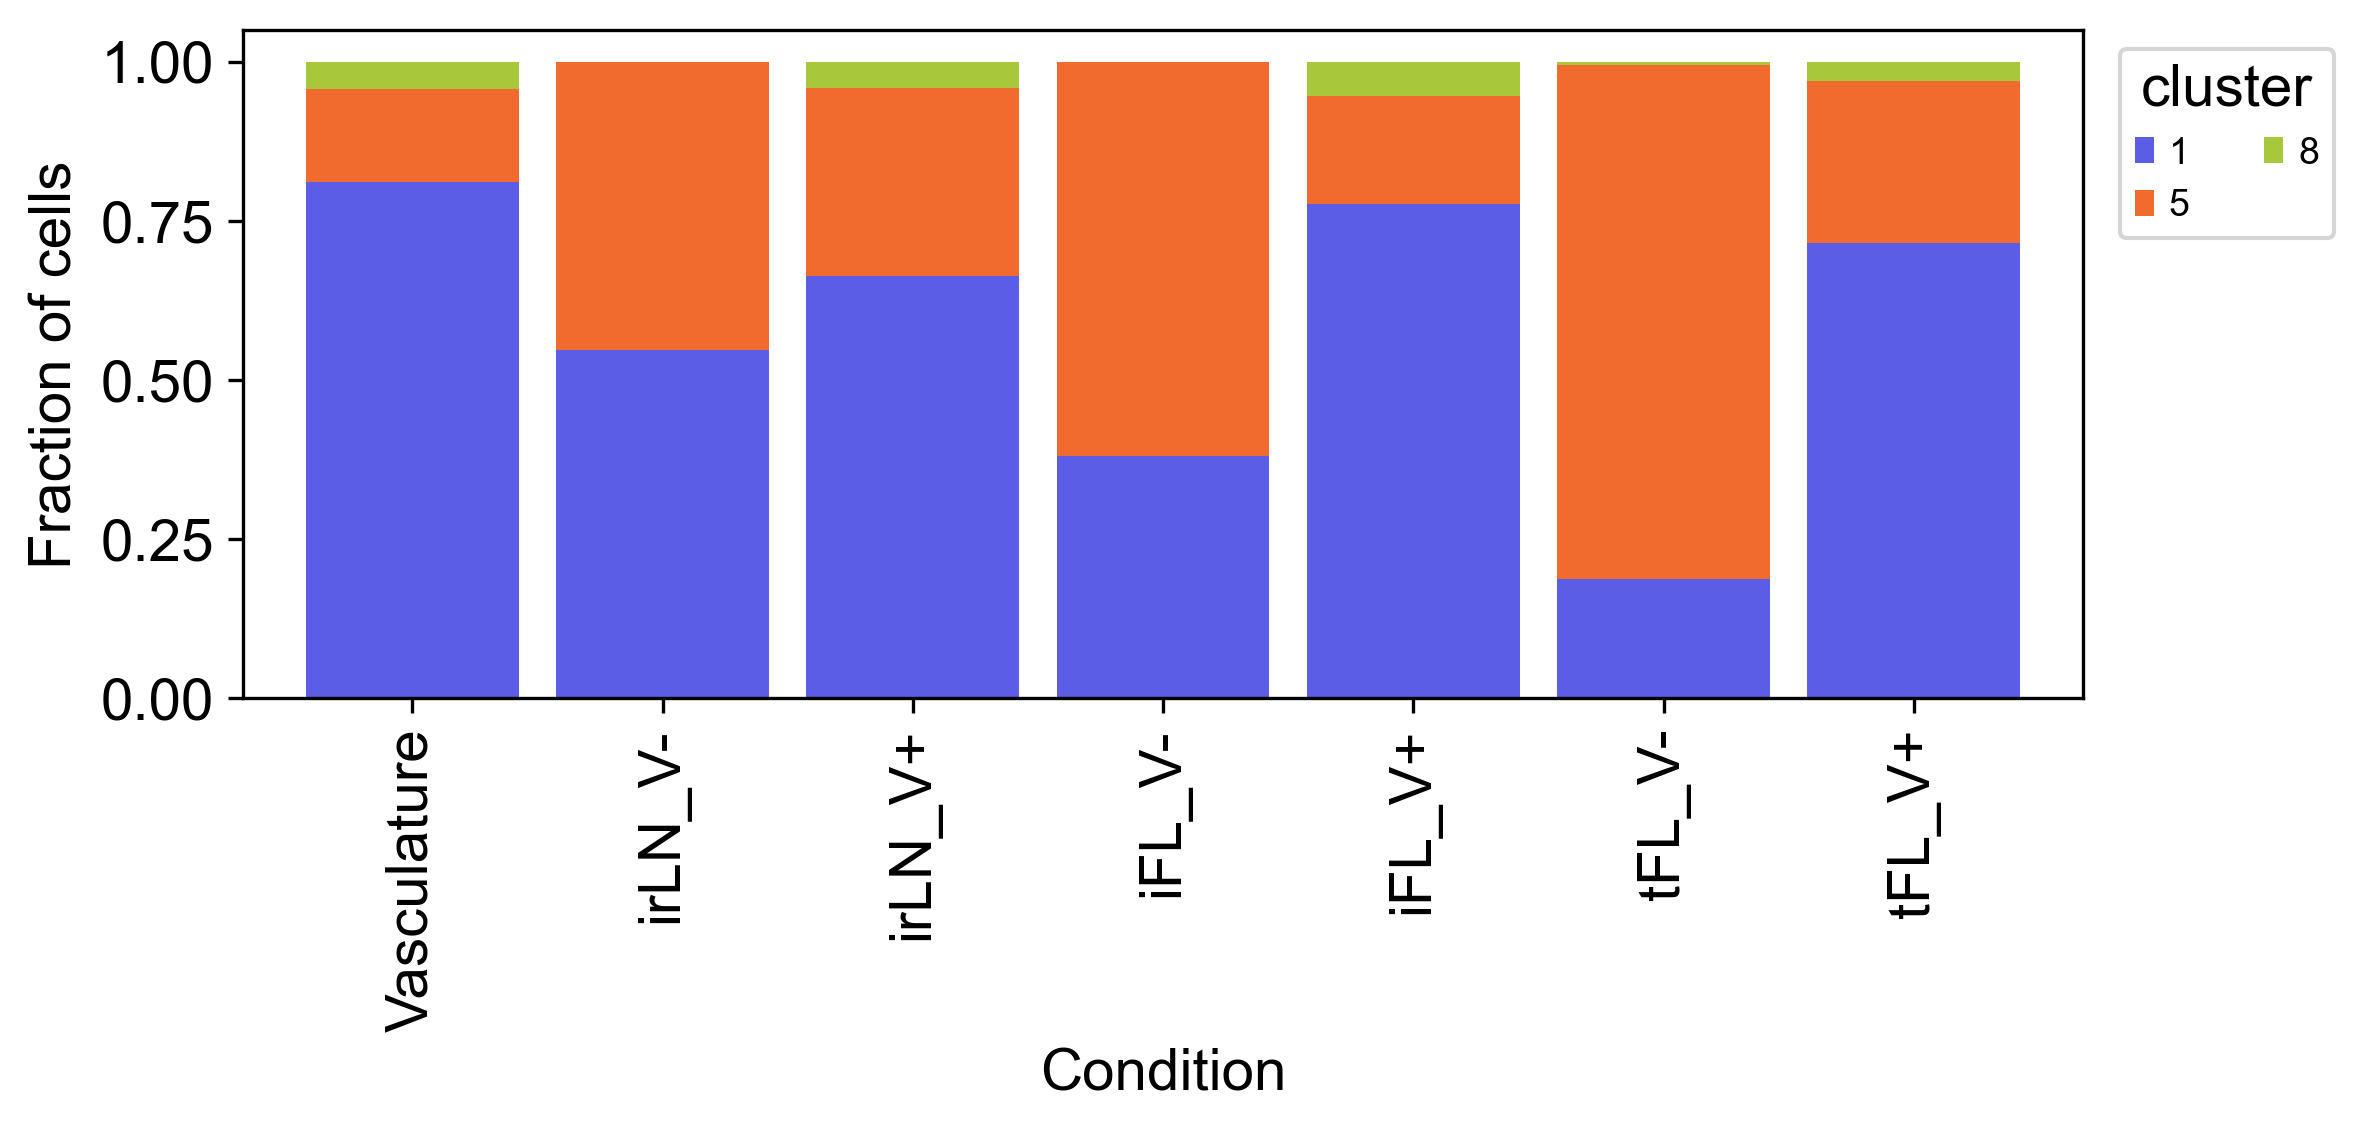

['tFL_V+', 'iFL_V+', 'tFL_V-', 'iFL_V-', 'irLN_V-', 'irLN_V+', 'Vasculature']
Categories (7, object): ['Vasculature', 'iFL_V+', 'tFL_V+', 'iFL_V-', 'tFL_V-', 'irLN_V+', 'irLN_V-']
['2', '3', '7']
Categories (3, object): ['2', '3', '7']
condition
Vasculature       1
iFL_V+         1360
tFL_V+         1200
iFL_V-         4752
tFL_V-         7184
irLN_V+         172
irLN_V-        1270
dtype: int64


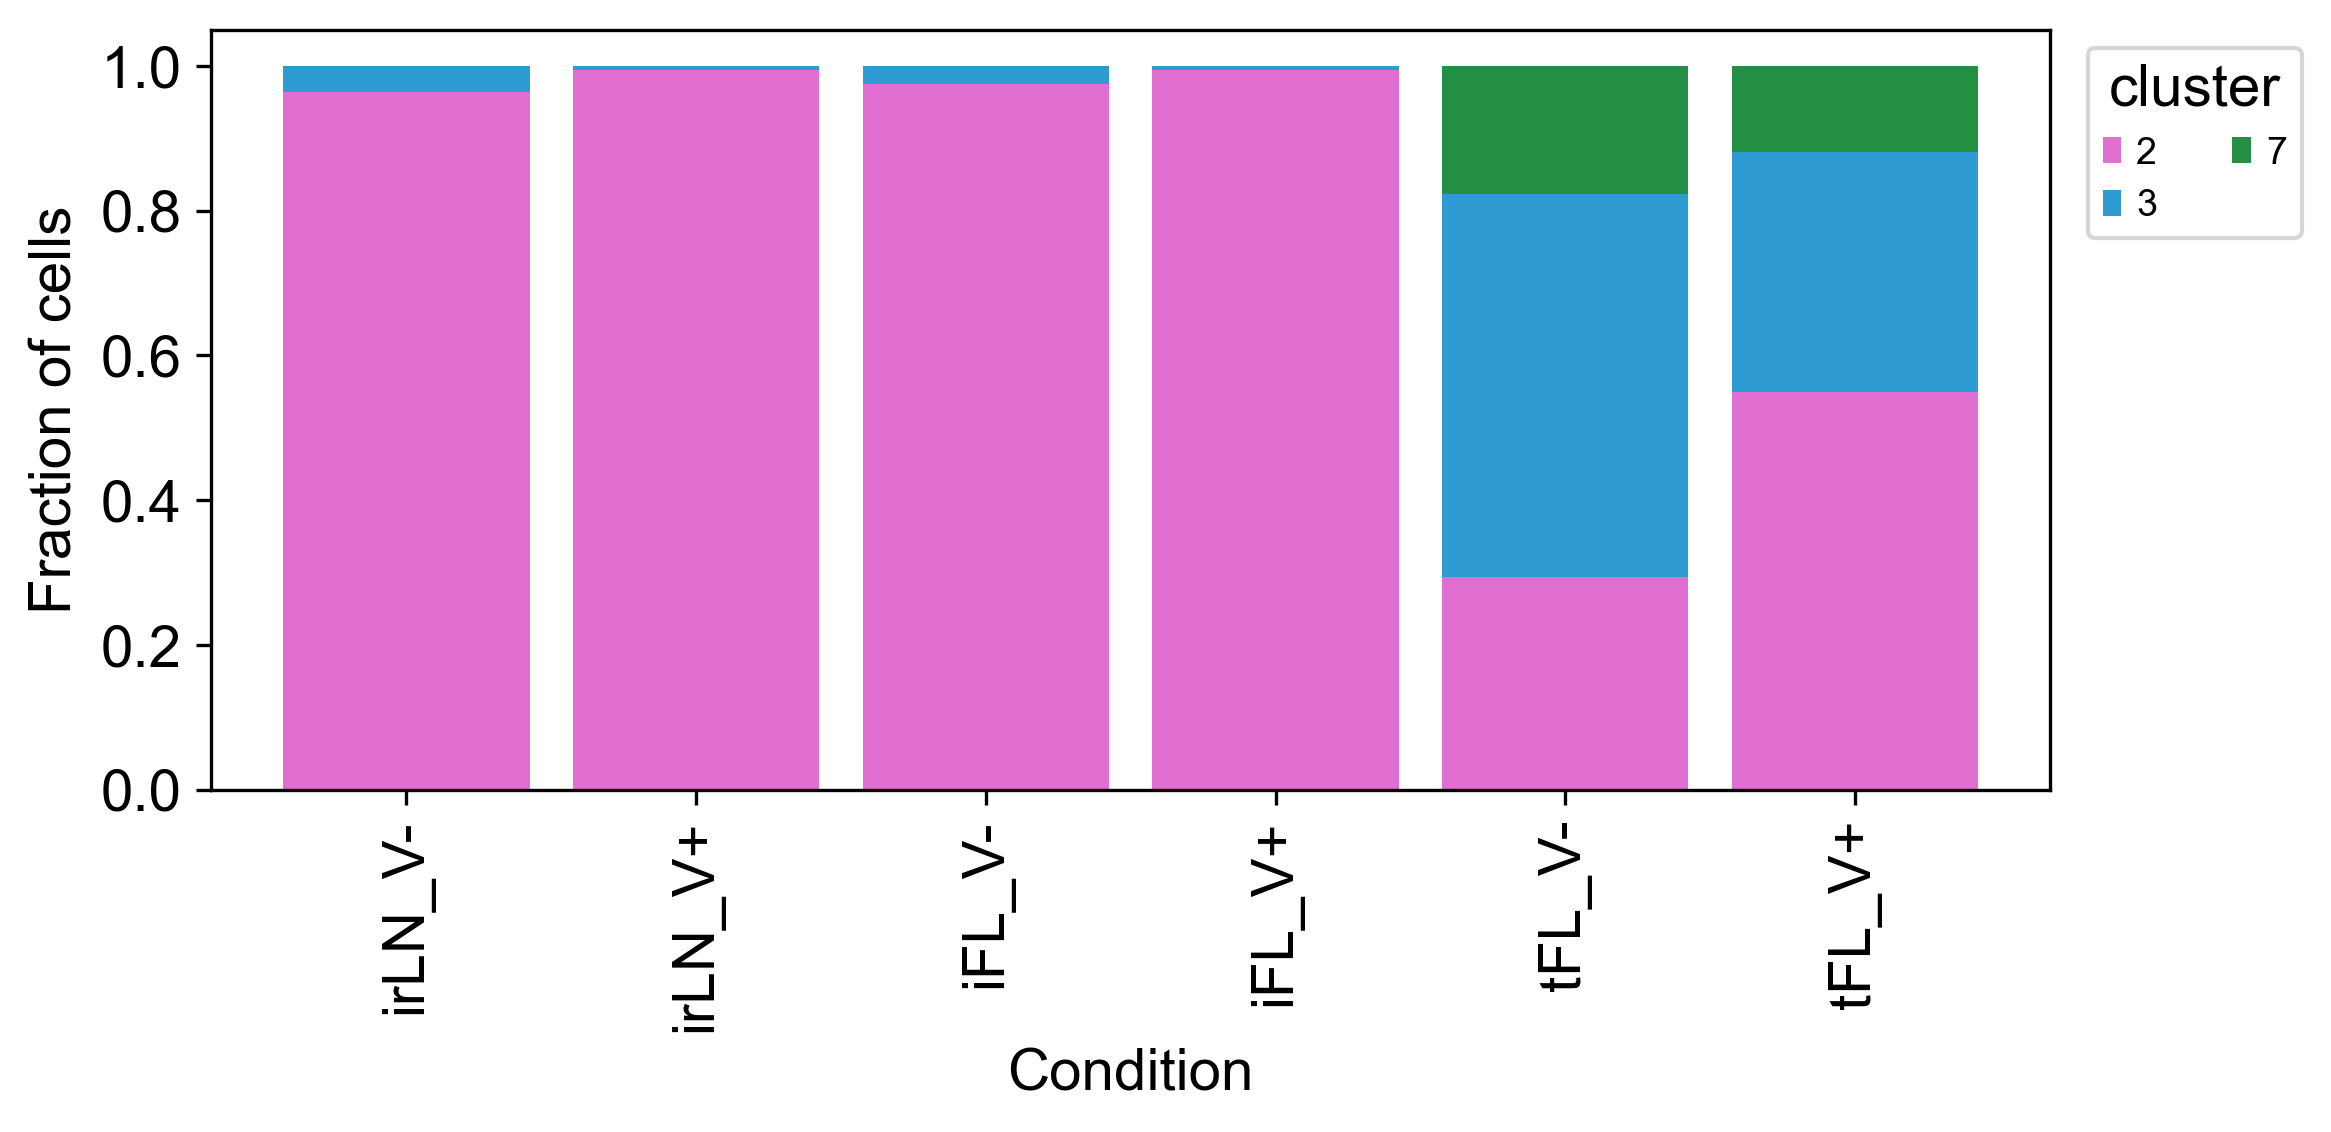

In [3]:
endothelial_cells = res_0_6[res_0_6.obs["clusters"].isin(["0", "6"])].copy()
fibroblast_cells = res_0_6[res_0_6.obs["clusters"].isin(["1", "5", "8"])].copy()
b_cells = res_0_6[res_0_6.obs["clusters"].isin(["2","3","7"])].copy()
order = [
    "Vasculature",
    "irLN_V-",
    "irLN_V+",
    "iFL_V-",
    "iFL_V+",
    "tFL_V-",
    "tFL_V+"
]

for i, cell_type in enumerate([endothelial_cells, fibroblast_cells, b_cells]):
    print(cell_type.obs["condition"].unique())
    print(cell_type.obs["clusters"].unique())
    print(cell_type.obs.groupby("condition").size())
    subset = cell_type[cell_type.obs["condition"].isin(cell_type.obs.groupby("condition").size()[lambda x: x>100].index.unique())].copy()
    comp = (
        pd.crosstab(
            subset.obs["condition"],
            subset.obs["clusters"],
            normalize="index"
        )
        .reindex([x for x in order if x in subset.obs.groupby("condition").size()[lambda x: x>100].index.unique()])
    )
    ax = comp.plot(kind="bar", stacked=True, figsize=(8, 4),  color=[cluster_colourmap[str(c)] for c in comp.columns], width=0.85, grid = False)
    ax.set_ylabel("Fraction of cells")
    ax.set_xlabel("Condition")
    ax.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(figdir, f"reordered_composition_per_condition_{i}.png"), bbox_inches="tight")
    plt.show()
    comp.round(3).to_csv(os.path.join(figdir, f"composition_per_condition_{i}.csv"))

In [ ]:
for i, cell_type in enumerate([endothelial_cells, fibroblast_cells, b_cells]):
    counts = cell_type.obs.groupby("condition").size()
    keep_conditions = counts[counts > 100].index
    subset = cell_type[cell_type.obs["condition"].isin(keep_conditions)].copy()

    comp = pd.crosstab(subset.obs["condition"], subset.obs["clusters"], normalize="index")
    raw_counts = subset.obs.groupby("condition").size().loc[comp.index]

    x = np.arange(len(comp))
    widths = raw_counts / raw_counts.max() * 0.8  # scale to fit nicely
    bottoms = np.zeros(len(comp))

    fig, ax = plt.subplots(figsize=(10, 4))

    for cluster in comp.columns:
        vals = comp[cluster].values
        ax.bar(x, vals, width=widths, bottom=bottoms, color=cluster_colourmap[str(cluster)], edgecolor="white", linewidth=0.5, label=str(cluster))
        bottoms += vals

    for xi, wi, total in zip(x, widths, raw_counts.values):
        ax.text(xi, 1.05, f"{total}", ha="center", va="bottom", fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(comp.index, rotation=0)
    ax.set_ylabel("Fraction of cells")
    ax.set_xlabel("Condition")
    ax.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=9)
    ax.grid(False)
    plt.tight_layout()
    plt.savefig(os.path.join(figdir, f"width_adjusted_composition_per_condition_{i}.png"), bbox_inches="tight")
    plt.show()

In [ ]:
sc.tl.rank_genes_groups(res_0_6, groupby="clusters", method="wilcoxon", use_raw=True, rankby_abs = True)
sc.pl.rank_genes_groups_dotplot( #plots the top 5 DEGs per cluster (by p value), coloured by their log fold change
    res_0_6, n_genes=5, values_to_plot="logfoldchanges", cmap="bwr",
    vmin=-4, vmax=4, colorbar_title="log fold change",
    save="_markers.png", show=True,
)

In [ ]:
# Canonical human immune markers grouped by lineage (lymph node / lymphoma context).
immune_markers = {
    "B cell": ["CD19", "MS4A1", "CD79A", "CD79B"],
    "Germinal center B": ["BCL6", "AICDA", "RGS13", "LMO2"],
    "FL B cell": ["BCL2", "MME"],          
    "Plasma": ["MZB1", "XBP1", "PRDM1", "SDC1"],
    "T cell": ["CD3D", "CD3E", "CD2"],
    "CD4 T": ["CD4", "IL7R"],
    "CD8 T": ["CD8A", "CD8B", "GZMK"],
    "Tfh": ["CXCL13", "PDCD1", "ICOS"],
    "NK": ["NKG7", "GNLY", "KLRD1"],
    "Myeloid/DC": ["LYZ", "CD68", "ITGAX"],
    "Endothelial": ["PECAM1", "VWF", "CDH5", "CLDN5"],          # blood vessels
    "Lymphatic endothelial": ["PROX1", "LYVE1", "PDPN"],       # lymphatic sinuses
    "Fibroblast/stromal": ["PDGFRA", "PDGFRB", "COL1A1", "COL3A1", "DCN", "LUM"],
    "FRC": ["ACTA2", "PDPN", "CCL19", "CCL21"],                 # fibroblastic reticular cells
    "FDC": ["CR2", "CR1", "FDCSP", "CLU"],                      # follicular dendritic cells (germinal centers)
    "Proliferating": ["MKI67", "TOP2A"],
}

# 5. Canonical marker annotation (drop genes absent from this dataset).
present = {k: [g for g in v if g in res_0_6.var_names] for k, v in immune_markers.items()}
present = {k: v for k, v in present.items() if v}

# Recompute the dendrogram for THIS resolution's clusters. It is cached in
# adata.uns and would otherwise be stale (wrong # categories) from a prior resolution.
sc.tl.dendrogram(res_0_6, groupby="clusters")
sc.pl.dotplot(res_0_6, present, groupby="clusters", standard_scale="var",
                dendrogram=True, save="_canonical_markers.png", show=True)


In [ ]:
individual_genes = pd.read_excel(r"z:\Bel\Marina_Side_Projects\scRNA\SIGNATURE PDLT.xlsx")

for gene in individual_genes.Gene:
    if gene not in res_0_6.var_names:
        print(f"Skipping {gene} — not in dataset")
        continue

    df = sc.get.obs_df(res_0_6, keys=[gene, "clusters"], use_raw=True)
    summary = (df.groupby("clusters")[gene].agg(mean_expr="mean", pct_expr=lambda x: (x > 0).mean() * 100, n_cells="size").sort_values("mean_expr", ascending=False))
    individual_genes.loc[individual_genes.Gene == gene, "Actual_Cluster"] = int(summary.index[0])



In [ ]:
individual_genes["Actual_Cluster"] = individual_genes["Actual_Cluster"].astype("Int64")  
individual_genes["Flag"] = individual_genes.apply(lambda row: True if row["Actual_Cluster"] != row["Predicted_Cluster"] else False, axis=1)

individual_genes.to_csv(r"individual_gene_clusters_annotated.csv", index=False)
individual_genes

In [ ]:
key_genes = [g for g in individual_genes.Gene if g in res_0_6.var_names]
sc.pl.umap(res_0_6, color=key_genes, ncols=4, cmap="Reds", use_raw=True,
            save="_key_genes.png", show=True)

In [ ]:
for gene in key_genes:
    sc.pl.violin(res_0_6, keys=gene, groupby="clusters", use_raw=True, stripplot=False, palette=cluster_colourmap, save=f"_{gene}_violin.png", show=False)


# Gene Signatures

In [ ]:
signature_df = pd.read_csv("marina_gene_signatures.csv")

# When use_raw=True, scoring happens against res_0_6.raw — filter against that.
gene_universe = res_0_6.raw.var_names if res_0_6.raw is not None else res_0_6.var_names

for sig in signature_df["signature"].unique():
    up = signature_df.query("signature == @sig and direction == 'up'")["gene"]
    down = signature_df.query("signature == @sig and direction == 'down'")["gene"]

    up = [g for g in up if g in gene_universe]
    down = [g for g in down if g in gene_universe]
    print(f"{sig}: {len(up)} up genes, {len(down)} down genes found")

    if not up and not down:
        print(f"  Skipping {sig} — no signature genes in dataset")
        continue

    if up:
        sc.tl.score_genes(res_0_6, up, score_name=f"{sig}_up", use_raw=True)
    if down:
        sc.tl.score_genes(res_0_6, down, score_name=f"{sig}_down", use_raw=True)

    # signed score (handle the case where one direction is empty)
    up_score = res_0_6.obs[f"{sig}_up"] if up else 0
    down_score = res_0_6.obs[f"{sig}_down"] if down else 0
    res_0_6.obs[f"{sig}_signed"] = up_score - down_score

    vmax = res_0_6.obs[f"{sig}_signed"].abs().quantile(0.99)
    # sc.pl.umap(
    #     res_0_6, color=f"{sig}_signed", cmap="RdBu_r",
    #     vmin=-vmax, vcenter=0, vmax=vmax,
    #     title=f"{sig} signature (up − down)",
    #     save=f"_{sig}_signature.png", show=True,
    # )
    conditions = list(res_0_6.obs.condition.cat.categories)
    fig, axes = plt.subplots(ncols=len(conditions), figsize=(4 * len(conditions), 4))
    axes = np.atleast_1d(axes).ravel()

    for ax, condition in zip(axes, conditions):
        sc.pl.umap(
            res_0_6[res_0_6.obs.condition == condition], color=f"{sig}_signed",
            cmap="bwr", use_raw=True, vmin=-vmax, vmax=vmax,
            colorbar_loc=None,               # suppress per-panel colorbars
            title=str(condition), frameon=False, show=False, ax=ax,
        )

    # One shared colorbar for the whole figure.
    sm = ScalarMappable(norm=Normalize(vmin=-vmax, vmax=vmax), cmap="RdBu_r")
    fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=f"{sig}_signed")
    fig.suptitle(f"{sig}_signed", y=1.02, x=0.55)

    fig.savefig(os.path.join(figdir, f"umap_{sig}_by_condition.png"), bbox_inches="tight")






# gene_dz_excel = pd.read_excel(r"c:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Genes_DZ.xlsx")
# gene_cc_excel = pd.read_excel(r"C:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Genes_from_Cellchatt.xlsx")
# all_genes = pd.concat([gene_dz_excel, gene_cc_excel], ignore_index=True)
# key_genes = [g for g in all_genes.Gene if g in res_0_2.var_names]

# conditions = list(res_0_2.obs.condition.cat.categories)
# cmap = "Reds"

# for gene in key_genes:
#     expr = sc.get.obs_df(res_0_2, keys=[gene], use_raw=True)[gene]
#     vmin, vmax = 0.0, float(expr.max())

#     fig, axes = plt.subplots(ncols=4, figsize=(4 * 4, 4))
#     axes = np.atleast_1d(axes).ravel()
#     for ax, condition in zip(axes, conditions):
#         sc.pl.umap(
#             res_0_2[res_0_2.obs.condition == condition], color=gene,
#             cmap=cmap, use_raw=True, vmin=vmin, vmax=vmax,
#             colorbar_loc=None,               # suppress per-panel colorbars
#             title=str(condition), frameon=False, show=False, ax=ax,
#         )

#     # One shared colorbar for the whole figure.
#     sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
#     fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=gene)
#     fig.suptitle(gene, y=1.02, x=0.55)
#     fig.savefig(os.path.join(figdir, f"umap_{gene}_by_condition.png"), bbox_inches="tight")
#     plt.show()

# Volcano Plots

In [ ]:
import re
from pydeseq2.default_inference import DefaultInference


def _safe_level(name):
    """pydeseq2 can't handle  '+', '-', or '_' 
     Conver to safe names e.g. 'iFL_V+' -> 'iFLVpos'."""
    return re.sub(r"[^0-9A-Za-z]", "", name.replace("+", "pos").replace("-", "neg"))


def pseudobulk_de(adata, cluster, cond_a, cond_b, sample_key="sample",
                  cond_key="condition", cluster_key="clusters",
                  layer="counts", min_cells=10):
    """Pseudobulk DE (cond_a vs cond_b) within one cluster. Positive log2FC = up in cond_a."""
    mask = (adata.obs[cluster_key] == cluster) & adata.obs[cond_key].isin([cond_a, cond_b])
    sub = adata[mask].copy()

    pb = dc.get_pseudobulk(
        sub, sample_col=sample_key, groups_col=None,
        layer=layer, mode="sum", min_cells=min_cells, min_counts=1000,
    )

    n = pb.obs[cond_key].value_counts()
    if n.get(cond_a, 0) < 2 or n.get(cond_b, 0) < 2:
        print(f"cluster {cluster}: not enough replicates "
              f"({cond_a}={n.get(cond_a,0)}, {cond_b}={n.get(cond_b,0)}) — skipping")
        return None

    sc.pp.filter_genes(pb, min_cells=1)

    # Overwrite "condition" with alphanumeric-only level names so pydeseq2 leaves them
    # untouched; astype(str) also drops the 5 unused categories from the full dataset.
    sa, sb = _safe_level(cond_a), _safe_level(cond_b)
    pb.obs[cond_key] = pb.obs[cond_key].astype(str).map({cond_a: sa, cond_b: sb}).astype("category")

    inference = DefaultInference(n_cpus=1)
    dds = DeseqDataSet(adata=pb, design_factors=cond_key, refit_cooks=True,
                       inference=inference)
    dds.deseq2()
    stat = DeseqStats(dds, contrast=[cond_key, sa, sb], inference=inference)  # cond_a vs cond_b
    stat.summary()
    res = stat.results_df.reset_index().rename(columns={"index": "gene"})
    res["cluster"] = cluster
    return res

In [ ]:
def volcano(df, cond_a, cond_b, cluster, lfc_thresh=1.0, padj_thresh=0.05, save=None):
    df = df.dropna(subset=["padj"]).copy()
    df["neglog10_padj"] = -np.log10(df["padj"].clip(lower=1e-300))
    up   = (df["log2FoldChange"] >=  lfc_thresh) & (df["padj"] < padj_thresh)
    down = (df["log2FoldChange"] <= -lfc_thresh) & (df["padj"] < padj_thresh)

    plt.figure(figsize=(6, 5))
    plt.scatter(df["log2FoldChange"], df["neglog10_padj"], s=6, c="lightgrey")
    plt.scatter(df.loc[up, "log2FoldChange"],   df.loc[up, "neglog10_padj"],   s=10, c="red",  label=f"up in {cond_a}")
    plt.scatter(df.loc[down, "log2FoldChange"], df.loc[down, "neglog10_padj"], s=10, c="blue", label=f"up in {cond_b}")
    plt.axhline(-np.log10(padj_thresh), ls="--", c="k", lw=0.6)
    plt.axvline( lfc_thresh, ls="--", c="k", lw=0.6)
    plt.axvline(-lfc_thresh, ls="--", c="k", lw=0.6)
    plt.xlabel("log2 fold change"); plt.ylabel("-log10 adjusted p-value")
    plt.title(f"Cluster {cluster}: {cond_a} vs {cond_b}")
    plt.legend(fontsize=8)
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()


from itertools import combinations

# All possible condition pairs (every condition vs every other condition).
conditions = list(res_0_6.obs["condition"].cat.categories)
pairs = list(combinations(conditions, 2))


all_results = []
for cluster in res_0_6.obs["clusters"].cat.categories[5:]:
    for cond_a, cond_b in pairs:
        res = pseudobulk_de(res_0_6, cluster, cond_a, cond_b)
        if res is not None:
            all_results.append(res)
            volcano(res, cond_a, cond_b, cluster,
                    save=os.path.join(figdir, f"volcano_c{cluster}_{cond_a}_vs_{cond_b}.png"))

if all_results:
    combined = pd.concat(all_results, ignore_index=True)
    combined.to_csv(os.path.join(figdir, "pseudobulk_DE_all.csv"), index=False)

In [ ]:
conditions = list(res_0_6.obs.condition.cat.categories)


In [ ]:

# gene_dz_excel = pd.read_excel(r"c:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Genes_DZ.xlsx")
# gene_cc_excel = pd.read_excel(r"C:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Genes_from_Cellchatt.xlsx")
# all_genes = pd.concat([gene_dz_excel, gene_cc_excel], ignore_index=True)
# key_genens = [g for g in all_genes.Gene if g in res_0_6.var_names]


conditions = list(res_0_6.obs.condition.cat.categories)
cmap = "Reds"

for gene in key_genes:
    expr = sc.get.obs_df(res_0_6, keys=[gene], use_raw=True)[gene]
    vmin, vmax = 0.0, float(expr.max())

    fig, axes = plt.subplots(ncols=4, figsize=(4 * 4, 4))
    axes = np.atleast_1d(axes).ravel()
    for ax, condition in zip(axes, conditions):
        sc.pl.umap(
            res_0_6[res_0_6.obs.condition == condition], color=gene,
            cmap=cmap, use_raw=True, vmin=vmin, vmax=vmax,
            colorbar_loc=None,               # suppress per-panel colorbars
            title=str(condition), frameon=False, show=False, ax=ax,
        )

    # One shared colorbar for the whole figure.
    sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
    fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=gene)
    fig.suptitle(gene, y=1.02, x=0.55)
    fig.savefig(os.path.join(figdir, f"umap_{gene}_by_condition.png"), bbox_inches="tight")
    plt.show()

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
result = res_0_6.uns['rank_genes_groups']
groups = result['names'].dtype.names

# Create a combined DataFrame of the top 10 genes for each cluster
top15_degs = pd.DataFrame(
    {group + '_' + key[:6]: result[key][group] 
     for group in groups for key in ['names', 'logfoldchanges', 'pvals_adj']}
).head(15)

# Display the dataframe
print(top15_degs)
samples = list(res_0_6.obs["sample"].unique())
cmap = "Reds"


for cluster in range(9):
    genes_of_interest = top15_degs[f"{cluster}_names"]  # Get the top genes for the current cluster
    key_genes = [gene for gene in genes_of_interest if gene in res_0_6.var_names]  # Filter genes that are present in the dataset
    for gene in key_genes:
        expr = sc.get.obs_df(res_0_6, keys=[gene], use_raw=True)[gene]
        vmin, vmax = 0.0, float(expr.max())

        fig, axes = plt.subplots(ncols=len(samples), figsize=(15 * 4, 4))
        axes = np.atleast_1d(axes).ravel()
        for ax, sample in zip(axes, samples):
            sc.pl.umap(
                res_0_6[res_0_6.obs["sample"] == sample], color=gene,
                cmap=cmap, use_raw=True, vmin=vmin, vmax=vmax,
                colorbar_loc=None,               # suppress per-panel colorbars
                title=str(sample), frameon=False, show=False, ax=ax,size=3
            ) # log2fold change is of the cluster relative to the mean of all other clusters
            # colorbar = actual expression, not the fold change (per cell expression value from that gene
            # dot colour = how much the gene is expressed in an individual cell (absolute level, not a comparison)

        # One shared colorbar for the whole figure.
        sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
        fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=gene)
        fig.suptitle(f"cluster {cluster}, gene {gene}", y=1.02, x=0.55)
        fig.savefig(os.path.join(figdir, f"umap_{gene}_by_sample_cluster{cluster}.png"), bbox_inches="tight")
        plt.show()

In [ ]:


# gene_dza_excel = pd.read_excel(r"c:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Genes_DZ.xlsx")
# gene_cc_excel = pd.read_excel(r"C:\Users\taylorhearn\Desktop\scRNAseq_Dorota\Genes_from_Cellchatt.xlsx")
# all_genes = pd.concat([gene_dz_excel, gene_cc_excel], ignore_index=True)
# key_genes = [g for g in all_genes.Gene if g in res_0_2.var_names]

samples = list(res_0_6.obs["sample"].unique())
cmap = "Reds"

for gene in key_genes:
    expr = sc.get.obs_df(res_0_6, keys=[gene], use_raw=True)[gene]
    vmin, vmax = 0.0, float(expr.max())

    fig, axes = plt.subplots(ncols=4, figsize=(4 * 4, 4))
    axes = np.atleast_1d(axes).ravel()
    for ax, sample in zip(axes, samples):
        sc.pl.umap(
            res_0_6[res_0_6.obs["sample"] == sample], color=gene,
            cmap=cmap, use_raw=True, vmin=vmin, vmax=vmax,
            colorbar_loc=None,               # suppress per-panel colorbars
            title=str(sample), frameon=False, show=False, ax=ax,
        )

    # One shared colorbar for the whole figure.
    sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
    fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=gene)
    fig.suptitle(gene, y=1.02, x=0.55)
    fig.savefig(os.path.join(figdir, f"umap_{gene}_by_condition.png"), bbox_inches="tight")
    plt.show()

In [ ]:

# names = ["endothelial_cells", "fibroblast_cells", "b_cells"]
# for i, cell_group in enumerate([endothelial_cells, fibroblast_cells, b_cells]):
#     cell_group.obs["clusters"] = cell_group.obs["clusters"].cat.remove_unused_categories()
#     sc.tl.rank_genes_groups(cell_group, groupby="clusters", method="wilcoxon", use_raw=True, rankby_abs=True)
#     sc.tl.dendrogram(cell_group, groupby="clusters")
#     # sc.pl.rank_genes_groups_heatmap(cell_group, n_genes=20, groupby='clusters', cmap='bwr')

#     sc.pl.rank_genes_groups_heatmap(
#         cell_group, n_genes=20, groupby="clusters",
#         standard_scale="var",     # scale each gene to [0, 1] so differences are visible
#         cmap="bwr",           # sequential map for one-sided data
#         show_gene_labels=True,
#     )
#     sc.pl.rank_genes_groups_dotplot( #plots the top 5 DEGs per cluster (by p value), coloured by their log fold change
#         cell_group, n_genes=20, values_to_plot="scores", cmap="bwr",
#         vmin=-4, vmax=4, colorbar_title="scores",
#         save=f"{names[i]}_markers.png", show=True,
#     )

names = ["endothelial_cells", "fibroblast_cells", "b_cells"]
for i, cell_group in enumerate([endothelial_cells, fibroblast_cells, b_cells]):
    cell_group.obs["clusters"] = cell_group.obs["clusters"].cat.remove_unused_categories()
    sc.tl.rank_genes_groups(cell_group, groupby="clusters", method="wilcoxon", use_raw=True, rankby_abs=True)
    sc.tl.dendrogram(cell_group, groupby="clusters")

    # Pool DEGs from every cluster, rank by |score| across all, keep top 20 unique genes.
    de = sc.get.rank_genes_groups_df(cell_group, group=None)   # group=None => all clusters
    de["abs_score"] = de["scores"].abs()
    top20 = (de.sort_values("abs_score", ascending=False)
               .drop_duplicates("names")
               .head(20)["names"].tolist())

    sc.pl.heatmap(
        cell_group, var_names=top20, groupby="clusters",
        standard_scale="var", cmap="bwr", dendrogram=True,
        show_gene_labels=True, save=f"_{names[i]}_top20_total.png",
    )

    sc.pl.rank_genes_groups_dotplot(
        cell_group, n_genes=20, values_to_plot="scores", cmap="bwr",
        vmin=-4, vmax=4, colorbar_title="scores",
        save=f"{names[i]}_markers.png", show=True,
    )

    sc.pl.rank_genes_groups_matrixplot(
    cell_group, n_genes=20, values_to_plot="scores",
    cmap="bwr", vmin=-4, vmax=4, colorbar_title="scores",
    dendrogram=True, save=f"{names[i]}_scores_matrix.png",
)